## Before you start

Run `python download_data.py` once from the project folder. It downloads the NASA
C-MAPSS files into `data/`, and the notebook only reads them — it never downloads
anything itself.

Already have a `data/` folder with the FD001 and FD002 files inside? Skip this step.

## Sensor guide

The data is simulated by NASA's C-MAPSS engine model: 21 sensors are recorded on every flight, plus sensor noise. Numbers, symbols, meanings and units below follow Table 2 of Saxena, Goebel, Simon & Eklund 2008, *Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation* — the paper that introduced this dataset — and the number is the sensor's position in the data file (columns 6 to 26). The FD001 column says whether the sensor is kept or dropped: a dropped sensor either never moves or moves only between two values, so it carries no trend.

| # | Symbol | What it measures | Unit | FD001 |
| --- | --- | --- | --- | --- |
| 1 | T2 | Total temperature at fan inlet | °R | dropped |
| 2 | T24 | Total temperature at low-pressure compressor outlet | °R | kept |
| 3 | T30 | Total temperature at high-pressure compressor outlet | °R | kept |
| 4 | T50 | Total temperature at low-pressure turbine outlet | °R | kept |
| 5 | P2 | Pressure at fan inlet | psia | dropped |
| 6 | P15 | Total pressure in bypass duct | psia | dropped |
| 7 | P30 | Total pressure at high-pressure compressor outlet | psia | kept |
| 8 | Nf | Physical fan speed | rpm | kept |
| 9 | Nc | Physical core speed | rpm | kept |
| 10 | epr | Engine pressure ratio (P50/P2) | not stated | dropped |
| 11 | Ps30 | Static pressure at high-pressure compressor outlet | psia | kept |
| 12 | phi | Ratio of fuel flow to Ps30 | pps/psi | kept |
| 13 | NRf | Corrected fan speed | rpm | kept |
| 14 | NRc | Corrected core speed | rpm | kept |
| 15 | BPR | Bypass ratio | not stated | kept |
| 16 | farB | Burner fuel-air ratio | not stated | dropped |
| 17 | htBleed | Bleed enthalpy | not stated | kept |
| 18 | Nf_dmd | Demanded fan speed | rpm | dropped |
| 19 | PCNfR_dmd | Demanded corrected fan speed | rpm | dropped |
| 20 | W31 | Coolant bleed, high-pressure turbine | lbm/s | kept |
| 21 | W32 | Coolant bleed, low-pressure turbine | lbm/s | kept |

A cycle is one operational cycle, which in this dataset is one flight, and there is one row per flight per engine.

The four sensors plotted below are 11 (Ps30), 4 (T50), 12 (phi) and 7 (P30).

## Introduction

This notebook asks one question: given an engine's sensor readings, how many cycles of life does it have left? It loads NASA's FD001 and FD002 run-to-failure data, checks that the files are what they claim, labels every recorded cycle with its remaining useful life, and shows what wear looks like across 100 engines. Then it scores a deliberately simple model, plain least squares on trajectory features built from the 14 sensors that actually move, against the dumbest possible guess, on both subsets.


## Imports and paths

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data")
TRAIN = DATA / "train_FD001.txt"
TEST = DATA / "test_FD001.txt"
RUL = DATA / "RUL_FD001.txt"


In [2]:
# One role palette and one type/size scale for every figure below.
STYLE = {
    "ink": "#1A1A1A", "muted": "#595959", "faint": "#8C8C8C", "rule": "#707070",
    "grid": "#E9E9E9", "edge": "#C9C9C9", "raw": "#B0B0B0",
    "rise": "#D55E00", "fall": "#0072B2", "band": "#9E9E9E66",  # drift direction, IQR band
    "size": (11.0, 7.6), "pair": (9.9, 5.5),  # 2x2 canvas, two-panel canvas
    "title": 13, "subtitle": 9, "panel": 10.5, "label": 10, "tick": 9, "tag": 9,
}
plt.rcParams.update({
    "font.size": STYLE["label"], "axes.titlesize": STYLE["panel"], "axes.labelsize": STYLE["label"],
    "xtick.labelsize": STYLE["tick"], "ytick.labelsize": STYLE["tick"], "axes.grid": True,
    "grid.color": STYLE["grid"], "grid.linewidth": 0.8, "axes.edgecolor": STYLE["edge"],
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
})


## Load data

In [3]:
COLS = ["unit", "cycle"] + [f"setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]

train = pd.read_csv(TRAIN, sep=r"\s+", header=None, names=COLS)
test = pd.read_csv(TEST, sep=r"\s+", header=None, names=COLS)
rul = pd.read_csv(RUL, sep=r"\s+", header=None, names=["RUL"]).squeeze()

## Sanity check

`data/readme.txt` numbers its column list up to "sensor measurement 26", but the file has only 26 columns in total — unit + cycle + 3 operational settings + 21 sensors — so 21 sensors is the correct count and nothing was truncated.

In [4]:
for name, df in [("train", train), ("test", test)]:
    print(f"{name}: shape={df.shape} engines={df.unit.nunique()} missing={int(df.isna().sum().sum())}")
print(f"rul: shape={rul.shape} missing={int(rul.isna().sum())}")
assert len(rul) == test["unit"].nunique() == 100
print("dtypes:", train.dtypes.value_counts().to_dict())
print(train.head(5).to_string())
print(rul.head(5).to_string())

train: shape=(20631, 26) engines=100 missing=0
test: shape=(13096, 26) engines=100 missing=0
rul: shape=(100,) missing=0
dtypes: {dtype('float64'): 22, dtype('int64'): 4}
   unit  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21
0     1      1    -0.0007    -0.0004      100.0    518.67    641.82   1589.70   1400.60     14.62     21.61    554.36   2388.06   9046.19        1.3      47.47     521.66    2388.02    8138.62     8.4195       0.03        392       2388      100.0      39.06    23.4190
1     1      2     0.0019    -0.0003      100.0    518.67    642.15   1591.82   1403.14     14.62     21.61    553.75   2388.04   9044.07        1.3      47.49     522.28    2388.07    8131.49     8.4318       0.03        392       2388      100.0      39.00    23.4236
2     1      3    -

## Train RUL

In [5]:
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
print(train.sample(5, random_state=0).to_string())
print(train["RUL"].describe().to_string())

       unit  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  RUL
13474    68     43     0.0003     0.0003      100.0    518.67    642.84   1585.15   1404.49     14.62     21.61    553.12   2388.10   9064.26        1.3      47.25     521.90    2388.08    8142.88     8.4486       0.03        392       2388      100.0      38.81    23.4724  156
1884      9    172     0.0041     0.0004      100.0    518.67    643.07   1593.98   1410.93     14.62     21.61    553.53   2388.01   9133.20        1.3      47.58     521.37    2388.08    8202.50     8.4565       0.03        393       2388      100.0      38.78    23.2069   29
17170    85     19    -0.0007     0.0001      100.0    518.67    642.56   1588.44   1403.63     14.62     21.61    553.79   2388.04   9043.28        1.3      47.30

## Sensor variability

Fifteen of the 21 sensors change at all. Fourteen are kept: sensor 6 only toggles between two adjacent readings (21.60 and 21.61), which is noise rather than a trend, so it goes with the six that never move.


In [6]:
sensors = [c for c in train.columns if c.startswith("sensor_")]
nuniq = train[sensors].nunique()
print(nuniq.to_frame("distinct").T.to_string())

dropped = [s for s in sensors if nuniq[s] <= 5]  # flat: no trend to learn
KEEP_SENSORS = [s for s in sensors if s not in dropped]
print("dropped flat sensors (<= 5 distinct values):", dropped)
print("kept sensors:", len(KEEP_SENSORS))


          sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21
distinct         1       310      3012      4051         1         2       513        53      6403          1        159        427         56       6078       1918          1         13          1          1        120       4745
dropped flat sensors (<= 5 distinct values): ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
kept sensors: 14


## Degradation by engine

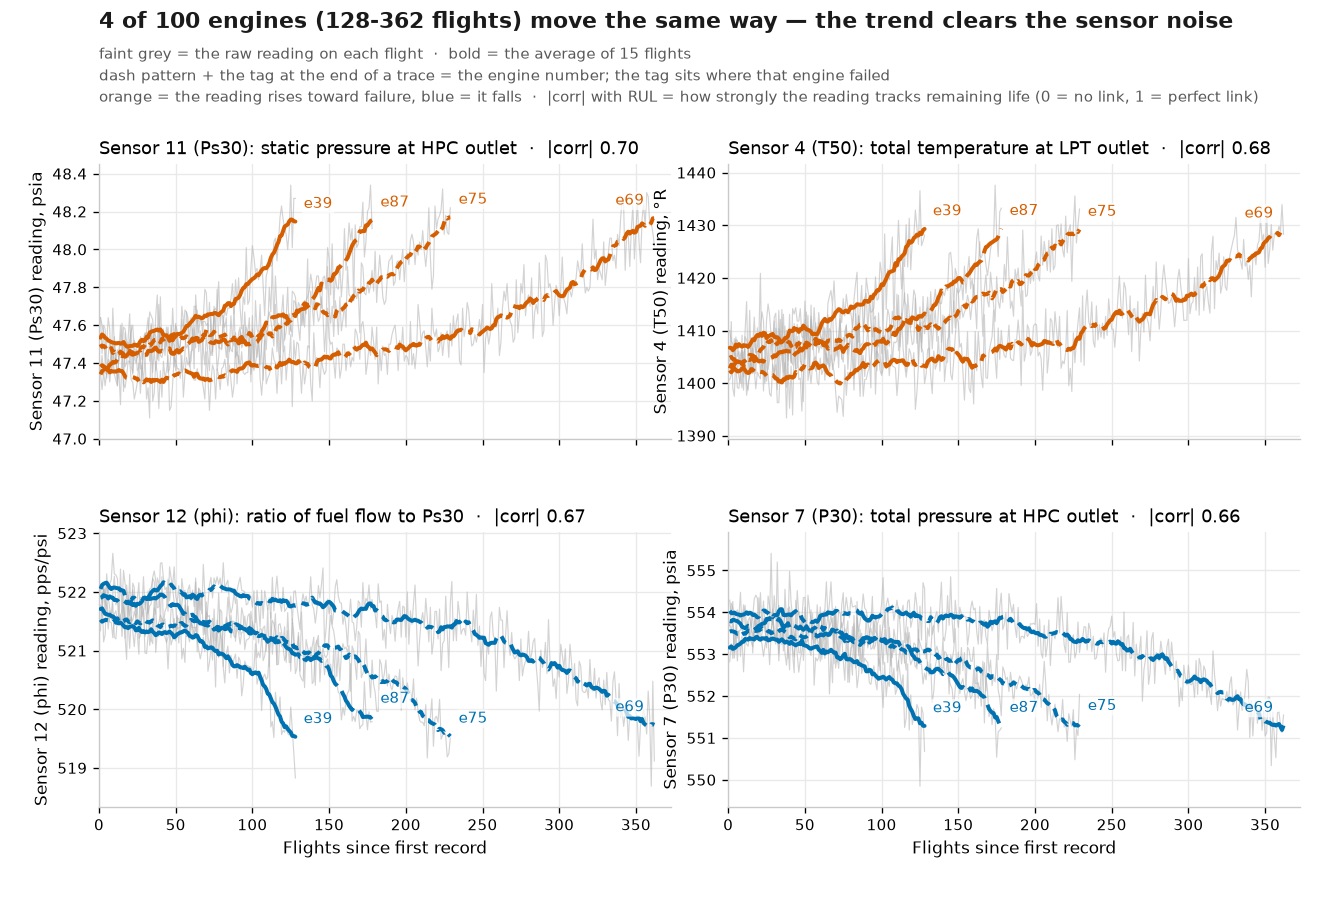

In [7]:
corr = train[KEEP_SENSORS].apply(lambda s: s.corr(train["RUL"]))
TOP = list(corr.abs().sort_values(ascending=False).head(4).index)
life = train.groupby("unit")["cycle"].max()
engines = [life.idxmin(), (life - life.quantile(0.25)).abs().idxmin(),
           (life - life.quantile(0.75)).abs().idxmin(), life.idxmax()]
ENGINE_DASH = ["-", (0, (6, 1.8)), (0, (2.2, 1.4)), (0, (9, 1.8, 2, 1.8))]
WIN = 15      # cycles in the centred rolling mean
LEFT = 0.075  # every figure starts its title and its left axis here

# The four sensors this cell plots, spelled the way the "Sensor guide" cell spells them.
SENSOR_INFO = {
    "sensor_11": ("11", "Ps30", "static pressure at HPC outlet", "psia"),
    "sensor_4": ("4", "T50", "total temperature at LPT outlet", "°R"),
    "sensor_12": ("12", "phi", "ratio of fuel flow to Ps30", "pps/psi"),
    "sensor_7": ("7", "P30", "total pressure at HPC outlet", "psia"),
}


def panel_title(s):
    """Panel heading: the sensor's number, symbol, plain-words meaning and |corr| with RUL."""
    num, sym, meaning, _ = SENSOR_INFO[s]
    return f"Sensor {num} ({sym}): {meaning}  ·  |corr| {abs(corr[s]):.2f}"


fig, axes = plt.subplots(2, 2, figsize=STYLE["size"], dpi=120, sharex=True)
fig.subplots_adjust(left=LEFT, right=0.985, top=0.82, bottom=0.115,
                    hspace=0.34, wspace=0.10)

for ax, s in zip(axes.ravel(), TOP):
    col = STYLE["rise"] if corr[s] < 0 else STYLE["fall"]
    num, sym, _, unit = SENSOR_INFO[s]
    for u, dash in zip(engines, ENGINE_DASH):
        d = train.loc[train["unit"] == u].sort_values("cycle")
        smooth = d[s].rolling(WIN, center=True, min_periods=3).mean()
        ax.plot(d["cycle"], d[s], color=STYLE["raw"], ls="-", lw=0.7, alpha=0.55, zorder=2)
        ax.plot(d["cycle"], smooth, color=col, ls=dash, lw=2.4, zorder=3,
                solid_capstyle="round")
        # engine tag at the end of its own trace: the longest one is placed
        # inside the axes so it cannot be clipped
        last = u == life.idxmax()
        ax.annotate(f"e{u}", (d["cycle"].iloc[-1], smooth.iloc[-1]),
                    xytext=(-6, 6) if last else (5, 6), textcoords="offset points",
                    ha="right" if last else "left", va="bottom",
                    fontsize=STYLE["tag"], color=col, zorder=4,
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.72))
    ax.set_title(panel_title(s), loc="left")
    ax.set_ylabel(f"Sensor {num} ({sym}) reading, {unit}")
    ax.margins(x=0.02, y=0.09)
    ax.set_xlim(0, life.max() * 1.03)
    ax.set_axisbelow(True)

for a in axes[1, :]:
    a.set_xlabel("Flights since first record")

fig.suptitle(f"{len(engines)} of {train['unit'].nunique()} engines "
             f"({int(life.min())}-{int(life.max())} flights) move the same way — "
             f"the trend clears the sensor noise",
             x=LEFT, y=0.988, ha="left", fontsize=STYLE["title"], fontweight="bold",
             color=STYLE["ink"])
fig.text(LEFT, 0.952,
         f"faint grey = the raw reading on each flight  ·  bold = the average of {WIN} flights\n"
         f"dash pattern + the tag at the end of a trace = the engine number; the tag sits where "
         f"that engine failed\n"
         f"orange = the reading rises toward failure, blue = it falls  ·  |corr| with RUL = how "
         f"strongly the reading tracks remaining life (0 = no link, 1 = perfect link)",
         ha="left", va="top", fontsize=STYLE["subtitle"], color=STYLE["muted"],
         linespacing=1.45)

## Fleet trend

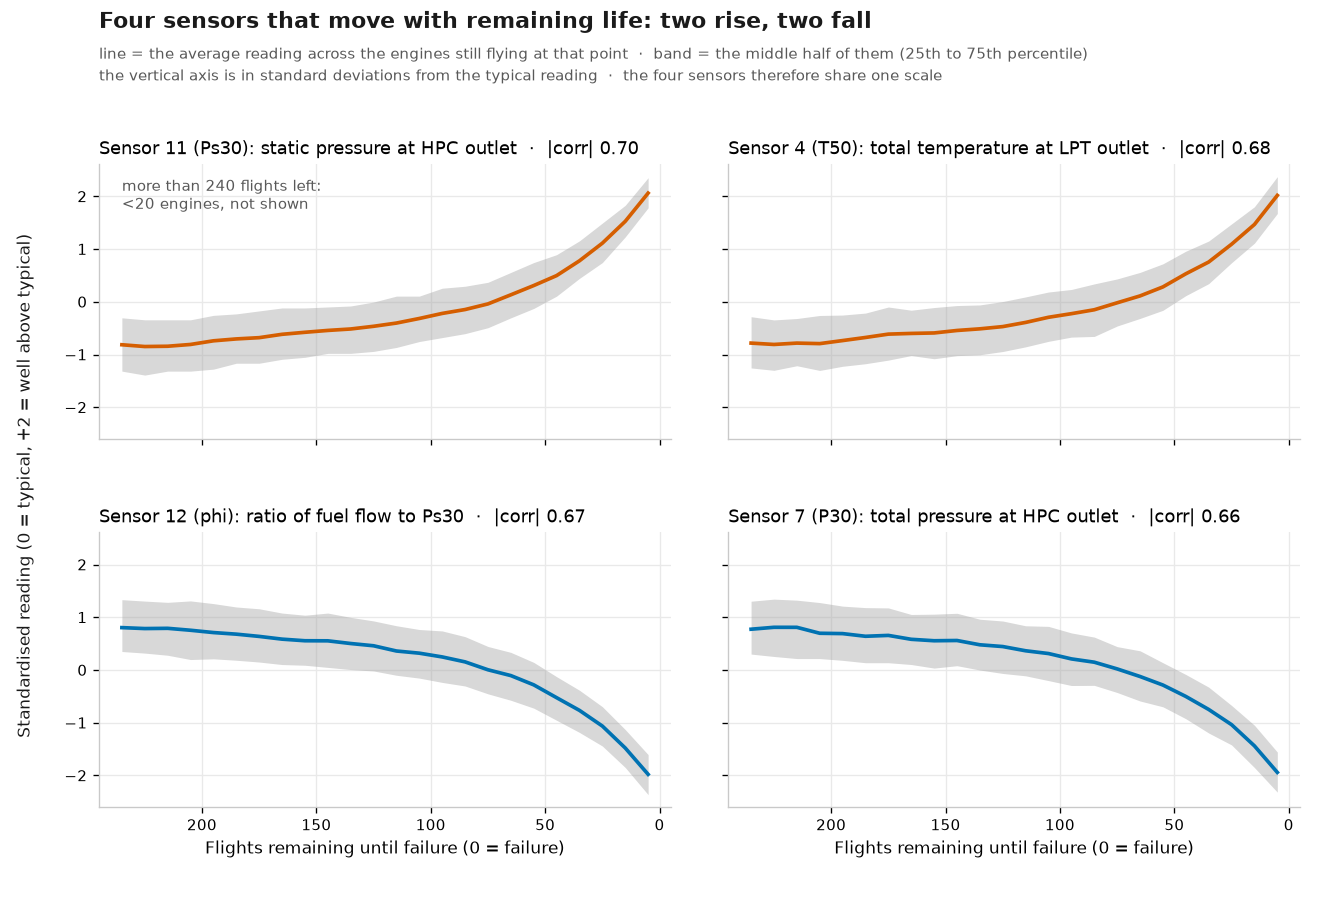

In [8]:
BIN = 10          # RUL bin width (cycles)
MIN_ENGINES = 20  # no mean is drawn where fewer engines than this remain
bins = pd.cut(train["RUL"], bins=range(0, int(train["RUL"].max()) + 20, BIN),
              include_lowest=True)
grp = train.groupby(bins, observed=True)
n_eng = grp["unit"].nunique()  # engines contributing to each RUL bin
x = np.array([b.mid for b in n_eng.index])
keep = n_eng.to_numpy() >= MIN_ENGINES
thin_from = float(n_eng.index[~keep][0].left) if (~keep).any() else float(x.max() + BIN / 2)
x_end = thin_from + BIN / 2  # padding only; the excluded tail is stated in words

fig, axes = plt.subplots(2, 2, figsize=STYLE["size"], dpi=120,
                         sharex=True, sharey=True)
fig.subplots_adjust(left=LEFT, right=0.985, top=0.82, bottom=0.115,
                    hspace=0.34, wspace=0.10)

for ax, s in zip(axes.ravel(), TOP):
    col = STYLE["rise"] if corr[s] < 0 else STYLE["fall"]
    z = (train[s] - train[s].mean()) / train[s].std()
    gz = z.groupby(bins, observed=True)
    mean = gz.mean().to_numpy()
    q1, q3 = gz.quantile(0.25).to_numpy(), gz.quantile(0.75).to_numpy()
    ax.fill_between(x[keep], q1[keep], q3[keep], color=STYLE["band"], lw=0, zorder=2)
    ax.plot(x[keep], mean[keep], color=col, lw=2.2, zorder=3)
    ax.set_title(panel_title(s), loc="left")
    ax.set_axisbelow(True)
    ax.set_xlim(x_end, -BIN / 2)

axes[0, 0].annotate(f"more than {thin_from:.0f} flights left:\n"
                    f"<{MIN_ENGINES} engines, not shown",
                    xy=(0.04, 0.95), xycoords="axes fraction", fontsize=STYLE["tag"],
                    color=STYLE["muted"], ha="left", va="top")
# the four panels share one standardised scale, so the axis gets one label, not four
fig.text(0.019, (0.82 + 0.115) / 2,
         "Standardised reading (0 = typical, +2 = well above typical)",
         rotation=90, va="center", ha="center", fontsize=STYLE["label"], color=STYLE["ink"])
for a in axes[1, :]:
    a.set_xlabel("Flights remaining until failure (0 = failure)")

fig.suptitle("Four sensors that move with remaining life: two rise, two fall",
             x=LEFT, y=0.988, ha="left", fontsize=STYLE["title"], fontweight="bold",
             color=STYLE["ink"])
fig.text(LEFT, 0.952,
         "line = the average reading across the engines still flying at that point  ·  "
         "band = the middle half of them (25th to 75th percentile)\n"
         "the vertical axis is in standard deviations from the typical reading  ·  "
         "the four sensors therefore share one scale",
         ha="left", va="top", fontsize=STYLE["subtitle"], color=STYLE["muted"],
         linespacing=1.45)

## Operating conditions in FD002

In [9]:
from sklearn.cluster import KMeans

SETTINGS = ["setting_1", "setting_2", "setting_3"]
SENSORS = [c for c in COLS if c.startswith("sensor_")]

probe = pd.read_csv(DATA / "train_FD002.txt", sep=r"\s+", header=None, names=COLS)
grid = probe[SETTINGS].to_numpy(float)
combos = probe[SETTINGS].round(1).drop_duplicates().shape[0]
inertia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(grid).inertia_ for k in range(1, 9)]
print(f"FD002 rows {len(probe):,}, distinct settings at 1 dp: {combos}")
print("k       " + "".join(f"{k:>10}" for k in range(1, 9)))
print("inertia " + "".join(f"{v:>10.4g}" for v in inertia))
print("ratio   " + "".join(f"{p:>10.3g}" for p in np.array(inertia[1:]) / np.array(inertia[:-1])))

FD002 rows 53,759, distinct settings at 1 dp: 7
k                1         2         3         4         5         6         7         8
inertia  2.259e+07 1.169e+07 1.865e+06 6.504e+05 2.466e+05    0.4107    0.3255    0.2743
ratio        0.517      0.16     0.349     0.379  1.67e-06     0.793     0.843


## Data layer: condition labels, per-condition z-score, loader

In [10]:
CONDITIONS = {"FD001": 1, "FD002": 6, "FD003": 1, "FD004": 6}   # FD002 inertia falls 2.5e5 -> 0.4 from k=5 to k=6
FLAT = 1e-9   # a sensor that does not move inside a condition stays at 0 instead of exploding


def load_subset(name, fit_units=None):
    """train, test, last-cycle test rows, RUL. Sensors are z-scored inside each condition.

    fit_units: the mean/std come from those training engines only, so a held-out engine never
    reaches the preprocessing."""
    def read(kind):
        return pd.read_csv(DATA / f"{kind}_{name}.txt", sep=r"\s+", header=None, names=COLS)

    train_sub, test_sub = read("train"), read("test")
    rul = pd.read_csv(DATA / f"RUL_{name}.txt", header=None, names=["RUL"]).squeeze()

    # the k-means keeps every training engine: it clusters settings, unsupervised, and never sees RUL
    km = KMeans(n_clusters=CONDITIONS[name], n_init=10, random_state=0).fit(train_sub[SETTINGS].to_numpy(float))
    train_sub["condition"] = km.labels_
    test_sub["condition"] = km.predict(test_sub[SETTINGS].to_numpy(float))

    # train statistics only; labels are 0..k-1 so [labels] broadcasts the right row onto every reading
    fit_rows = train_sub if fit_units is None else train_sub[train_sub["unit"].isin(fit_units)]
    mean = fit_rows.groupby("condition")[SENSORS].mean()
    std = fit_rows.groupby("condition")[SENSORS].std().mask(lambda s: s <= FLAT, 1.0)
    for frame in (train_sub, test_sub):
        labels = frame["condition"].to_numpy()
        frame[SENSORS] = (frame[SENSORS].to_numpy(float) - mean.to_numpy()[labels]) / std.to_numpy()[labels]

    train_sub["RUL"] = train_sub.groupby("unit")["cycle"].transform("max") - train_sub["cycle"]
    last = test_sub.sort_values(["unit", "cycle"]).groupby("unit").tail(1).reset_index(drop=True)
    return train_sub, test_sub, last, rul

## One condition must be a no-op

In [11]:
fd001 = load_subset("FD001")[0]
moving = [s for s in SENSORS if train[s].std() > FLAT]
before = (train[moving] - train[moving].mean()) / train[moving].std()
print(f"FD001: {len(moving)} moving sensors, max |within-condition - global| = "
      f"{np.abs(fd001[moving].to_numpy() - before.to_numpy()).max():.1e}")

fd002, test002, last002, rul002 = load_subset("FD002")
print(f"FD002: train {fd002.shape}, test {test002.shape}, last {last002.shape}, "
      f"RUL {len(rul002)}, conditions {fd002['condition'].nunique()}")

FD001: 15 moving sensors, max |within-condition - global| = 9.0e-11
FD002: train (53759, 28), test (33991, 27), last (259, 27), RUL 259, conditions 6


## Trajectory features

In [12]:
WIN = 20  # cycles in both the rolling mean and the change


def features(frame):
    """Per engine, sorted by cycle: value, WIN-cycle trailing mean, WIN-cycle change."""
    d = frame.sort_values(["unit", "cycle"])
    by_engine = d.groupby("unit")[KEEP_SENSORS]
    avg = by_engine.transform(lambda s: s.rolling(WIN, min_periods=1).mean())  # trailing only
    # early rows have no t-WIN reading, so they use the engine's first one: no NaN, no dropped rows
    change = d[KEEP_SENSORS] - by_engine.shift(WIN).fillna(by_engine.transform("first"))
    out = pd.concat([d[KEEP_SENSORS], avg.add_suffix(f"_avg{WIN}"),
                     change.add_suffix(f"_d{WIN}")], axis=1)
    return out.loc[frame.index]  # caller's row order: masks keep lining up


FEATURES = [f"{s}{suffix}" for s in KEEP_SENSORS for suffix in ("", f"_avg{WIN}", f"_d{WIN}")]
print(f"{len(FEATURES)} features = {len(KEEP_SENSORS)} sensors x (value, {WIN}-cycle mean, {WIN}-cycle change)")
print(FEATURES)

42 features = 14 sensors x (value, 20-cycle mean, 20-cycle change)
['sensor_2', 'sensor_2_avg20', 'sensor_2_d20', 'sensor_3', 'sensor_3_avg20', 'sensor_3_d20', 'sensor_4', 'sensor_4_avg20', 'sensor_4_d20', 'sensor_7', 'sensor_7_avg20', 'sensor_7_d20', 'sensor_8', 'sensor_8_avg20', 'sensor_8_d20', 'sensor_9', 'sensor_9_avg20', 'sensor_9_d20', 'sensor_11', 'sensor_11_avg20', 'sensor_11_d20', 'sensor_12', 'sensor_12_avg20', 'sensor_12_d20', 'sensor_13', 'sensor_13_avg20', 'sensor_13_d20', 'sensor_14', 'sensor_14_avg20', 'sensor_14_d20', 'sensor_15', 'sensor_15_avg20', 'sensor_15_d20', 'sensor_17', 'sensor_17_avg20', 'sensor_17_d20', 'sensor_20', 'sensor_20_avg20', 'sensor_20_d20', 'sensor_21', 'sensor_21_avg20', 'sensor_21_d20']


## One model path for any subset

In [13]:
def score_subset(name):
    """Fit on 4 of 5 engines, score the held-out rows and the last cycle of every test engine."""
    units = np.sort(load_subset(name)[0]["unit"].unique())
    held_units = units[::5]  # every fifth engine, as before
    # the normalisation learns from the fitting engines only: a held-out engine must not
    # reach the mean or the std, or the score flatters itself
    inner, inner_test, _, inner_rul = load_subset(name, fit_units=np.setdiff1d(units, held_units))
    X = features(inner).to_numpy(float)
    y = inner["RUL"].to_numpy(float)
    held = inner["unit"].isin(held_units).to_numpy()

    mean, std = X[~held].mean(axis=0), X[~held].std(axis=0)  # standardise on fitting rows only
    A = np.column_stack([np.ones(len(X)), (X - mean) / std])
    coef = np.linalg.lstsq(A[~held], y[~held], rcond=None)[0]
    mean_y = y[~held].mean()

    rows = inner_test.groupby("unit")["cycle"].idxmax()  # last recorded cycle per engine
    Xt = features(inner_test).loc[rows].to_numpy(float)
    truth = pd.Series(inner_rul.to_numpy(float), index=np.arange(1, len(inner_rul) + 1)).loc[
        inner_test.loc[rows, "unit"]].to_numpy(float)
    pred = np.clip(np.column_stack([np.ones(len(Xt)), (Xt - mean) / std]) @ coef, 0, None)

    def rmse(p, t):
        return float(np.sqrt(np.mean((p - t) ** 2)))

    matched = held & (y <= inner_rul.max())  # held-out cycles in this subset's own test life range
    return {"fit_rows": int((~held).sum()), "held_rows": int(held.sum()),
            "matched_max": float(inner_rul.max()),
            "held_rmse": rmse(np.clip(A[held] @ coef, 0, None), y[held]),
            "held_base": rmse(np.full(held.sum(), mean_y), y[held]),
            "matched_rmse": rmse(np.clip(A[matched] @ coef, 0, None), y[matched]),
            "matched_base": rmse(np.full(matched.sum(), mean_y), y[matched]),
            "test_rmse": rmse(pred, truth), "test_base": rmse(np.full(len(truth), mean_y), truth),
            "mean_pred": float(pred.mean()), "mean_truth": float(truth.mean()),
            "bias": float((pred - truth).mean()), "pred": pred, "truth": truth}

In [14]:
scores = {}
for name in ("FD001", "FD002"):
    s = scores[name] = score_subset(name)
    print(f"{name} fitting rows: {s['fit_rows']}")
    print(f"{name} held-out rows: {s['held_rows']}")
    print(f"{name} held-out RMSE: {s['held_rmse']:.1f} cycles")
    print(f"{name} always-guess-the-average RMSE: {s['held_base']:.1f} cycles")
    print(f"{name} held-out RMSE, RUL<={s['matched_max']:.0f} only: {s['matched_rmse']:.1f} cycles")
    print(f"{name} always-guess-the-average on the same rows: {s['matched_base']:.1f} cycles")
    print(f"{name} test RMSE: {s['test_rmse']:.1f} cycles")
    print(f"{name} always-guess-the-average RMSE on test: {s['test_base']:.1f} cycles")
    print(f"{name} mean prediction {s['mean_pred']:.1f} vs mean truth {s['mean_truth']:.1f} cycles")
    print(f"{name} bias: {s['bias']:+.1f} cycles")

FD001 fitting rows: 16262
FD001 held-out rows: 4369
FD001 held-out RMSE: 44.8 cycles
FD001 always-guess-the-average RMSE: 71.0 cycles
FD001 held-out RMSE, RUL<=145 only: 27.6 cycles
FD001 always-guess-the-average on the same rows: 54.1 cycles
FD001 test RMSE: 28.3 cycles
FD001 always-guess-the-average RMSE on test: 51.8 cycles
FD001 mean prediction 93.7 vs mean truth 75.5 cycles
FD001 bias: +18.2 cycles
FD002 fitting rows: 42614
FD002 held-out rows: 11145
FD002 held-out RMSE: 41.0 cycles
FD002 always-guess-the-average RMSE: 69.8 cycles
FD002 held-out RMSE, RUL<=194 only: 32.6 cycles
FD002 always-guess-the-average on the same rows: 56.5 cycles
FD002 test RMSE: 33.5 cycles
FD002 always-guess-the-average RMSE on test: 59.8 cycles
FD002 mean prediction 92.1 vs mean truth 81.2 cycles
FD002 bias: +10.9 cycles


## How the features were chosen

The 14 sensors and the 20-cycle mean and change were kept because they did better on held-out engines cut at an arbitrary cycle, but not by much: about one cycle on each subset, which sits inside the two-cycle spread the next-but-one section reports. They stay because a trailing slope is the first thing an engineer would expect to matter, and this page says plainly how little it buys. The test score never chose a feature set: it is one 100-engine draw, reported and never tuned on.


In [15]:
FEATURE_SETS = {"14": [c for c in FEATURES if not c.endswith((f"_avg{WIN}", f"_d{WIN}"))], "42": FEATURES}
for name in ("FD001", "FD002"):
    units = np.sort(load_subset(name)[0]["unit"].unique())
    held = units[::5]  # same fifth as everywhere else, kept out of the normalisation below
    frame = load_subset(name, fit_units=np.setdiff1d(units, held))[0]
    F = features(frame).assign(RUL=frame["RUL"].to_numpy(), unit=frame["unit"].to_numpy())
    engines = {u: F[F["unit"] == u] for u in held}
    fit = F[~F["unit"].isin(held)]
    for label, cols in FEATURE_SETS.items():
        mean, std = fit[cols].mean().to_numpy(), fit[cols].std().to_numpy()
        model = np.linalg.lstsq(np.column_stack([np.ones(len(fit)), (fit[cols].to_numpy(float) - mean) / std]),
                                fit["RUL"].to_numpy(float), rcond=None)[0]
        rng = np.random.default_rng(0)
        err = []
        for _ in range(25):
            cut = pd.DataFrame([engines[u].iloc[rng.integers(5, len(engines[u]))] for u in held])
            X = np.column_stack([np.ones(len(cut)), (cut[cols].to_numpy(float) - mean) / std])
            err.append(np.sqrt(np.mean((np.clip(X @ model, 0, None) - cut["RUL"].to_numpy()) ** 2)))
        print(f"{name} random-cut RMSE, {label} features: {np.mean(err):.1f} cycles")

FD001 random-cut RMSE, 14 features: 39.6 cycles
FD001 random-cut RMSE, 42 features: 38.6 cycles
FD002 random-cut RMSE, 14 features: 39.9 cycles
FD002 random-cut RMSE, 42 features: 39.4 cycles


## How sure is it?

One pooled half-width per subset: ±45.9 cycles on FD001 and ±49.8 on FD002. It is the 80th percentile of `|prediction − truth|` over 25-draw random cuts of 20 held-out engines, taken from a separate random seed to the feature-choice draws, so the width is not calibrated on the same draws that picked the features, and it never touches the test set. It is a nominal 80% promise, not a hard bound, and it rests on 20 engines x 25 draws, so it is coarse by a few cycles. Measured against the official answers it covers 85% of FD001's engines and 84% of FD002's, wider than promised, which is the honest direction: the model's mistakes are not symmetric. The printed coverage is a check, never a tuning knob.


In [16]:
INTERVALS = {}  # the policy cell reads these; nothing is copied by hand


def interval(name):
    """One pooled half-width from held-out engines cut at random cycles; coverage is the check."""
    units = np.sort(load_subset(name)[0]["unit"].unique())
    held = units[::5]
    # the normalisation must learn from the fitting engines only, as in predict.py
    frame = load_subset(name, fit_units=np.setdiff1d(units, held))[0]
    F = features(frame).assign(RUL=frame["RUL"].to_numpy(), unit=frame["unit"].to_numpy())
    engines = {u: F[F["unit"] == u] for u in held}
    fit = F[~F["unit"].isin(held)]
    X = fit[FEATURES].to_numpy(float)
    mean, std = X.mean(axis=0), X.std(axis=0)
    model = np.linalg.lstsq(np.column_stack([np.ones(len(X)), (X - mean) / std]),
                            fit["RUL"].to_numpy(float), rcond=None)[0]

    rng = np.random.default_rng(1)  # not the seed-0 draws the feature-choice cell selected on
    preds, truths = [], []
    for _ in range(25):
        cut = pd.DataFrame([engines[u].iloc[rng.integers(5, len(engines[u]))] for u in held])
        Xc = np.column_stack([np.ones(len(cut)), (cut[FEATURES].to_numpy(float) - mean) / std])
        preds += list(np.clip(Xc @ model, 0, None))
        truths += list(cut["RUL"].to_numpy())
    q = float(np.quantile(np.abs(np.array(preds) - np.array(truths)), 0.8))

    s = scores[name]
    INTERVALS[name] = {"half": q, "coverage": float(np.mean(np.abs(s["pred"] - s["truth"]) <= q))}
    print(f"{name} 80% interval: ±{q:.1f} cycles")
    print(f"{name} coverage on the test engines: {INTERVALS[name]['coverage']:.0%}")


for name in ("FD001", "FD002"):
    interval(name)


FD001 80% interval: ±45.9 cycles
FD001 coverage on the test engines: 85%
FD002 80% interval: ±49.8 cycles
FD002 coverage on the test engines: 84%


## How stable is that number?

Five grouped folds over the training engines, repeated five times with a fresh random cycle cut,
give one RMSE per draw, so the `±` is the luck a single score hides: a gap between two models
smaller than roughly two of those spreads is not evidence. Engines never straddle a fold, so no
engine is ever scored against its own history. The per-condition z-score is refit inside every
fold, on the four fitting folds' engines only, so a held-out engine never reaches the
preprocessing. The regime line pools all 25 held-out draws and
shows where the error lives, which is what one overall number hides.


In [17]:
from sklearn.model_selection import GroupKFold

def repeated_cv(name):
    """5 grouped folds x 5 repeats: fit on all cycles of the fitting engines, score a held cut each."""
    frame = load_subset(name)[0]
    F = features(frame).assign(RUL=frame["RUL"].to_numpy(), unit=frame["unit"].to_numpy(),
                               cycle=frame["cycle"].to_numpy())
    low = F[F["cycle"] >= 5]
    rmses, draws = [], []
    for repeat in range(5):
        cut = low.assign(pick=np.random.default_rng(100 + repeat).random(len(low))).sort_values("pick")
        cut = cut.groupby("unit", sort=False).head(1)  # one random cycle per engine, never before 5
        keys = list(zip(cut["unit"].to_numpy(), cut["cycle"].to_numpy()))  # row each engine is scored at
        y, pred = cut["RUL"].to_numpy(float), np.empty(len(cut))
        for fit_idx, held_idx in GroupKFold(n_splits=5).split(cut, groups=cut["unit"]):
            fit_units = np.sort(cut["unit"].to_numpy()[fit_idx])
            tr = load_subset(name, fit_units=fit_units)[0]  # preprocessing refit on the 4 fitting folds
            G = features(tr).assign(RUL=tr["RUL"].to_numpy(), unit=tr["unit"].to_numpy(),
                                    cycle=tr["cycle"].to_numpy()).set_index(["unit", "cycle"])
            fit = G.index.get_level_values("unit").isin(fit_units)  # every cycle of those engines
            Xf = G.loc[fit, FEATURES].to_numpy()
            mu, sd = Xf.mean(axis=0), Xf.std(axis=0)
            A = np.column_stack([np.ones(len(Xf)), (Xf - mu) / sd])
            coef = np.linalg.lstsq(A, G.loc[fit, "RUL"].to_numpy(float), rcond=None)[0]
            Bh = G.loc[keys, FEATURES].to_numpy()[held_idx]
            B = np.column_stack([np.ones(len(held_idx)), (Bh - mu) / sd])
            pred[held_idx] = np.clip(B @ coef, 0, None)
        draws.append((pred, y))
        rmses.append(np.sqrt(np.mean((pred - y) ** 2)))
    print(f"{name} repeated grouped CV: {np.mean(rmses):.1f} ± {np.std(rmses, ddof=1):.1f} cycles (5 folds x 5 repeats)")
    truth, sq = np.concatenate([t for _, t in draws]), np.concatenate([(p - t) ** 2 for p, t in draws])
    bin_of = np.digitize(truth, [50, 100, 150])  # 0-50, 50-100, 100-150, 150+
    bands = [f"{np.sqrt(sq[bin_of == i].mean()):.1f}" if (bin_of == i).any() else "n/a" for i in range(4)]
    print(f"{name} RMSE by true life: 0-50: {bands[0]} | 50-100: {bands[1]} | 100-150: {bands[2]} | 150+: {bands[3]}")

for name in ("FD001", "FD002"):
    repeated_cv(name)


FD001 repeated grouped CV: 41.5 ± 2.2 cycles (5 folds x 5 repeats)
FD001 RMSE by true life: 0-50: 28.1 | 50-100: 45.2 | 100-150: 29.9 | 150+: 57.3
FD002 repeated grouped CV: 41.0 ± 2.4 cycles (5 folds x 5 repeats)
FD002 RMSE by true life: 0-50: 28.3 | 50-100: 43.1 | 100-150: 28.5 | 150+: 59.8


## Where the model fails

The model leans high: on average it over-predicts by 10.9 cycles. The lean is not flat: about +2 close to failure, near +30 with 40 to 80 cycles left, and negative beyond roughly 140 cycles, down to −56 for engines with 180 or more. That bias accounts for 11% of the squared error, so the other 89% is scatter, which is what the second panel shows. Both panels show the same 259 test engines as points, not lines.


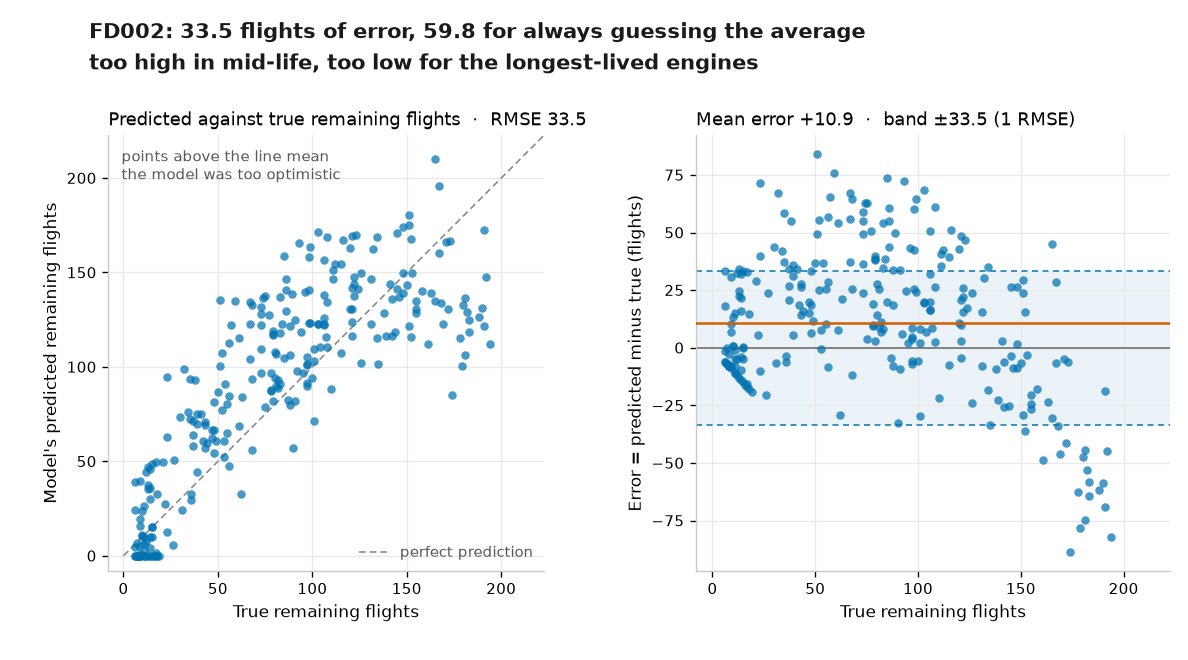

In [18]:
s = scores["FD002"]  # headline subset
truth, pred = s["truth"], s["pred"]
err = pred - truth
bias, rmse_test, baseline_test = s["bias"], s["test_rmse"], s["test_base"]
EDGE_PAD = 8.0  # small margin so the clipped-at-zero predictions stay whole
SPAN_PAD = 1.06  # room for the point at the top-right of the diagonal
lo = -EDGE_PAD
span = float(max(truth.max(), pred.max())) * SPAN_PAD
y_lo, y_hi = float(err.min()) - EDGE_PAD, float(err.max()) + EDGE_PAD

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=STYLE["pair"], dpi=120)
fig.subplots_adjust(left=LEFT, right=0.985, top=0.795, bottom=0.135, wspace=0.28)

# Panel 1: the same point cloud the RMSE is computed on, against the perfect diagonal.
ax1.plot([0, span], [0, span], color=STYLE["faint"], lw=1.0, ls=(0, (4, 2.4)),
         label="perfect prediction", zorder=1)
ax1.scatter(truth, pred, s=26, color=STYLE["fall"], alpha=0.72, linewidths=0, zorder=2)
ax1.set_xlim(lo, span)
ax1.set_ylim(lo, span)
ax1.set_aspect("equal", adjustable="box")
ax1.set_xlabel("True remaining flights")
ax1.set_ylabel("Model's predicted remaining flights")
ax1.set_title(f"Predicted against true remaining flights  ·  RMSE {rmse_test:.1f}", loc="left")
# the point cloud hugs the diagonal, so the key to the line sits in the empty corner
ax1.legend(loc="lower right", frameon=False, fontsize=STYLE["tag"],
           handlelength=1.9, labelcolor=STYLE["muted"], borderaxespad=0.3)
ax1.annotate("points above the line mean\nthe model was too optimistic",
             xy=(0.03, 0.97), xycoords="axes fraction", ha="left", va="top",
             fontsize=STYLE["tag"], color=STYLE["muted"])
ax1.set_axisbelow(True)

# Panel 2: error only. Dashed band = the scored RMSE, orange line = the lean.
ax2.axhspan(-rmse_test, rmse_test, color=STYLE["fall"], alpha=0.08, lw=0, zorder=0)
for edge in (-rmse_test, rmse_test):
    ax2.axhline(edge, color=STYLE["fall"], lw=0.9, ls=(0, (4, 3)), zorder=1)
ax2.axhline(0, color=STYLE["rule"], lw=1.0, zorder=1)
ax2.axhline(bias, color=STYLE["rise"], lw=1.5, zorder=3)
ax2.scatter(truth, err, s=26, color=STYLE["fall"], alpha=0.72, linewidths=0, zorder=2)
ax2.set_xlim(lo, span)
ax2.set_ylim(y_lo, y_hi)
ax2.set_xlabel("True remaining flights")
ax2.set_ylabel("Error = predicted minus true (flights)")
ax2.set_title(f"Mean error {bias:+.1f}  ·  band ±{rmse_test:.1f} (1 RMSE)", loc="left")
ax2.set_axisbelow(True)

fig.suptitle(f"FD002: {rmse_test:.1f} flights of error, {baseline_test:.1f} for always guessing the average\n"
             f"too high in mid-life, too low for the longest-lived engines",
             x=LEFT, y=0.975, va="top", ha="left", linespacing=1.5,
             fontsize=12.5, fontweight="bold", color=STYLE["ink"])

In [ ]:
## What to do with the number

A remaining-life number is only useful if it drives a decision, so the notebook turns it into
one. The decision uses the pessimistic end of the interval, not the middle, because
over-promising life is the expensive mistake. The four bands, stated plainly: 5 cycles or
fewer on the lower bound means ground the engine; up to 20, inspect before the next flight;
up to 60, plan the maintenance window; beyond that, monitor. This is a demonstration policy
for the notebook, not airworthiness guidance: a real fleet needs maintenance-interval and
dispatch-reliability rules from its operator.

In [19]:
half = INTERVALS["FD002"]["half"]  # FD002 80% half-width from the interval cell: the lower bound
p10 = np.maximum(0.0, scores["FD002"]["pred"] - half)  # pessimistic end, never negative
BANDS = [("GROUND", 5), ("INSPECT", 20), ("PLAN", 60), ("MONITOR", np.inf)]  # limits on p10
counts = np.diff([0] + [int((p10 <= limit).sum()) for _, limit in BANDS])  # each band's slice
assert int(counts.sum()) == len(p10)  # every test engine lands in exactly one band
print(f"FD002 decisions on the {len(p10)} test engines")
for (name, _), count in zip(BANDS, counts):
    print(f"  {name:<7}: {count} engines ({count / len(p10):.0%})")

FD002 decisions on the 259 test engines
  GROUND : 66 engines (25%)
  INSPECT: 16 engines (6%)
  PLAN   : 60 engines (23%)
  MONITOR: 117 engines (45%)


## Conclusions

Fourteen of the 21 sensors carry the story: some climb steadily as an engine wears, others fall. Each one enters the model three times — its value, its trailing 20-cycle mean and its 20-cycle change, all of them looking backwards only — and a straight line through those reaches an RMSE of 33.5 cycles on the 259 FD002 test engines, against 59.8 for always guessing the fleet average; the FD001 sanity case gives 28.3 against 51.8. The model is still systematically optimistic, about 11 cycles high, worst with 40 to 80 cycles of life left, and that bias is only 11% of the squared error: the rest is scatter, and scatter is what a better model should attack first.
